# National spend bundles with interrupted time series

You launch one national plan that raises search spend, cuts TV spend and adds video. Sales rise. The decision to keep the entire plan calls for one comparison with usual spend. The decision to keep video calls for a second comparison with the same search and TV plan without video.

Use CausalPy's {class}`~causalpy.InterruptedTimeSeries` to estimate the gap after the national launch. Then use simulations to see when that gap is evidence about the whole plan and why one launch leaves the channel split unidentified. The {doc}`geo spend bundles example <synthetic-control-geo-spend-bundles-pymc>` shows how assigning different plans to different markets can answer the video question.

In [1]:
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import MaxNLocator, StrMethodFormatter

import causalpy as cp

%matplotlib inline
%config InlineBackend.figure_format = "retina"

logging.getLogger("pymc").setLevel(logging.WARNING)
plt.style.use("seaborn-v0_8-whitegrid")
FIG_WIDTH, FIG_HEIGHT = 8, 3.2
CHANNEL_COLORS = {"Search": "#0072B2", "TV": "#A34A00", "Video": "#007D5E"}
OBSERVED_COLOR, BASELINE_COLOR = "#252525", "#0072B2"

PRE_WEEKS, POST_WEEKS = 104, 12
LAUNCH = 0
WEEKS = np.arange(-PRE_WEEKS, POST_WEEKS)
POST = WEEKS >= LAUNCH
DATA_SEED, FIT_SEED = 708, 1708
N_REPLICATIONS = 24

## Set the spend plan and the comparison

A bundle is a prespecified spend path for any number of channels. Each channel can rise, fall or stay unchanged. Here $A$ is a search increase, $B$ is a TV cut, and $C$ is a video increase. The reallocation transfers USD 10,000 per week from TV to search, and a separate reserve funds USD 5,000 per week of extra video. Under usual spend, weekly budgets stay at USD 20,000 for search, USD 50,000 for TV and USD 10,000 for video. Both paths share those amounts for 104 weeks before launch. The $ABC$ plan starts at week 0 and runs through week 11.

**Figure.** Weekly spend around launch by channel under the launched plan (solid) and usual spend (dashed after launch).

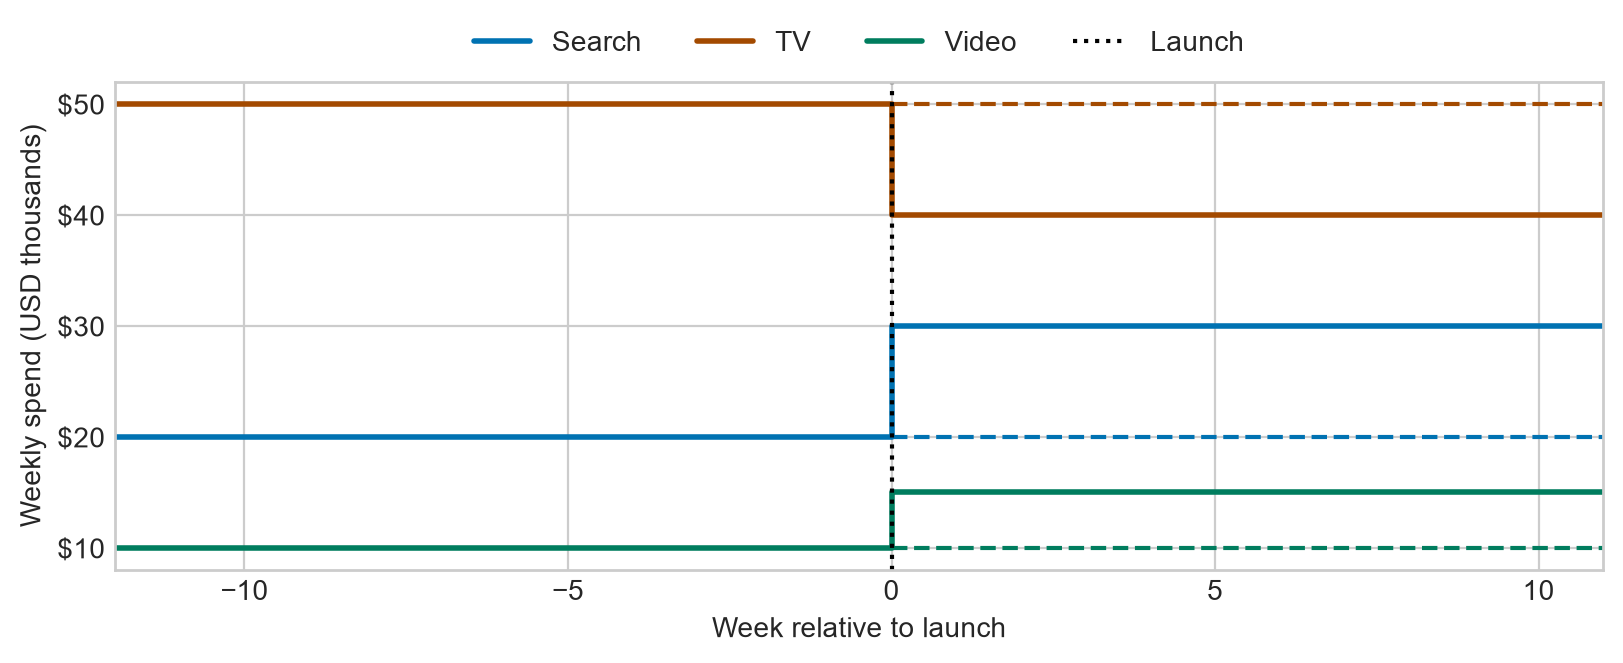

In [2]:
usual_spend = pd.Series({"Search": 20, "TV": 50, "Video": 10})
spend_change = pd.Series({"Search": 10, "TV": -10, "Video": 5})
spend = pd.DataFrame(
    usual_spend.to_numpy() + POST[:, None] * spend_change.to_numpy(),
    index=WEEKS,
    columns=usual_spend.index,
)

fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT), layout="constrained")
for channel, color in CHANNEL_COLORS.items():
    ax.step(WEEKS, spend[channel], where="post", color=color, label=channel, lw=2)
    ax.hlines(
        usual_spend[channel],
        WEEKS[POST][0],
        WEEKS[-1],
        color=color,
        linestyle="--",
        linewidth=1.5,
    )
ax.axvline(LAUNCH, color="black", linestyle=":", label="Launch")
ax.set(
    xlim=(-12, WEEKS[-1]),
    xlabel="Week relative to launch",
    ylabel="Weekly spend (USD thousands)",
)
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.legend(ncols=4, loc="lower center", bbox_to_anchor=(0.5, 1))
plt.show()

The TV cut pays for the search increase dollar for dollar. The reserve makes it feasible to add video while holding both of those changes fixed.

Write $M(b)$ for mean expected weekly sales under plan $b$, averaging the 12 launch weeks equally for this national market and holding calendar dates, pre-launch history and unaffected predictors fixed. The target is the **total bundle lift** $M(ABC)-M(0)$ in sales per week, where $0$ denotes usual spend. When both expected trajectories are modeled, apply the inverse link to each one separately and take their paired difference within each posterior draw.

## Estimate the national observed gap

In an {term}`interrupted time series design`, the pre-launch fit projects expected sales under usual spend. This is the {term}`counterfactual` for the launch weeks. The public ITS result subtracts that untreated expectation from realized sales. We call the difference the **observed gap**. A modeled expected effect would also require a fitted mean under the launched plan.

To interpret the gap as evidence of bundle lift, we need a credible projection of the stable untreated trajectory, no response in advance of launch and no unaccounted event that changes sales at the same time. A good pre-launch fit alone cannot establish these assumptions. {cite:p}`lopezbernal2017its`

The simulator plants a linear trend, a calendar demand cycle and autocorrelated weekly noise. The $ABC$ schedule increases expected sales by 12 each launch week. The baseline formula uses time and the calendar cycle, which the spend plan leaves unchanged. The shifted channel spends never enter the baseline fit.

In [3]:
BUNDLE_LIFT, COMMON_SHOCK = 12, 8
AR_COEFFICIENT, NOISE_SD = 0.45, 2.5


def simulate_bundle(rng):
    trend = WEEKS / 52
    season = np.sin(2 * np.pi * WEEKS / 52)
    untreated_mean = 100 + 2 * trend + 4 * season
    noise = np.empty(len(WEEKS))
    noise[0] = rng.normal(0, NOISE_SD)
    innovations = rng.normal(
        0, NOISE_SD * np.sqrt(1 - AR_COEFFICIENT**2), len(WEEKS) - 1
    )
    for week, innovation in enumerate(innovations, start=1):
        noise[week] = AR_COEFFICIENT * noise[week - 1] + innovation
    return pd.DataFrame(
        {
            "sales": untreated_mean + noise + BUNDLE_LIFT * POST,
            "trend": trend,
            "season": season,
        },
        index=pd.Index(WEEKS, name="obs_ind"),
    )


bundle_rng = np.random.default_rng(DATA_SEED)
worked_data = simulate_bundle(bundle_rng)

In [4]:
def national_its(data, formula, sample_seed):
    return cp.InterruptedTimeSeries(
        data,
        treatment_time=LAUNCH,
        formula=formula,
        model=cp.pymc_models.LinearRegression(
            sample_kwargs={"random_seed": sample_seed, "progressbar": False}
        ),
    )


bundle_formula = "sales ~ 1 + trend + season"
worked_its = national_its(worked_data, bundle_formula, FIT_SEED)

In [5]:
worked_its.fit();

**Figure.** Observed weekly sales and the posterior mean and pointwise 94% highest density interval for expected sales under usual spend. The dotted line marks launch.

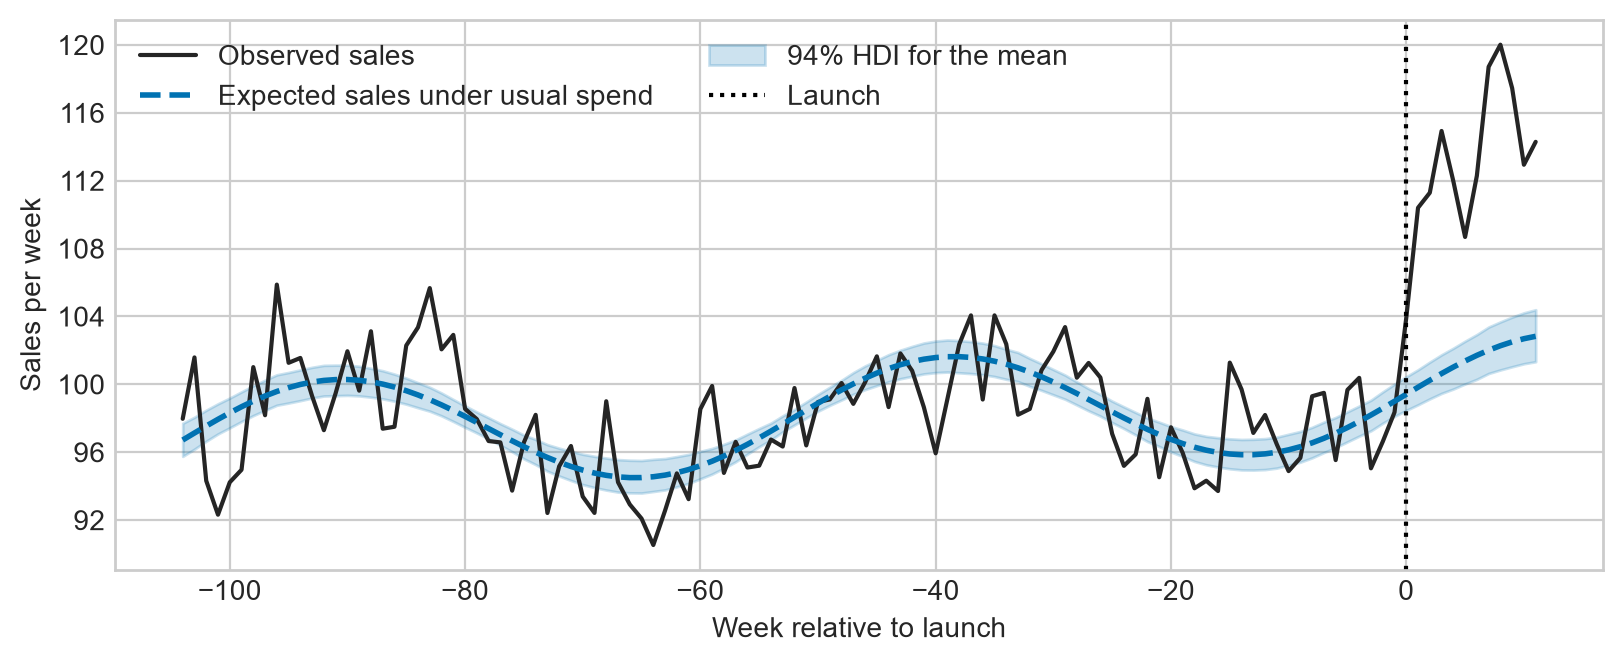

In [6]:
plot_data = worked_its.get_plot_data()
fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT), layout="constrained")
ax.plot(
    plot_data.index, plot_data["sales"], color=OBSERVED_COLOR, label="Observed sales"
)
ax.plot(
    plot_data.index,
    plot_data["prediction"],
    color=BASELINE_COLOR,
    linestyle="--",
    lw=2,
    label="Expected sales under usual spend",
)
ax.fill_between(
    plot_data.index,
    plot_data["pred_hdi_lower_94"],
    plot_data["pred_hdi_upper_94"],
    color=BASELINE_COLOR,
    alpha=0.20,
    label="94% HDI for the mean",
)
ax.axvline(LAUNCH, color="black", linestyle=":", label="Launch")
ax.set(xlabel="Week relative to launch", ylabel="Sales per week")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.legend(ncols=2, loc="upper left")
plt.show()

The fitted usual-spend trajectory continues the trend and seasonal cycle into the launch weeks. Its band describes uncertainty in the modeled mean. The fitted Gaussian regression treats residuals as independent, while the simulator makes them autocorrelated. We check point recovery across independent series below. This exercise makes no claim about calibration of the ITS band for autocorrelated data.

## Compare two explanations for the same launch

Suppose a competitor closes at the same time as launch, bringing eight additional sales per week even under usual spend. In the simulation we can compare the same launch with and without that shock. We keep the pre-launch fit, its untreated posterior draws and all weekly noise fixed. The true lift from the bundle remains 12 sales per week in either case. A baseline that misses the shock faces an expected gap of 20 in the shocked case.

In [7]:
def paired_gaps(fitted_its):
    baseline = fitted_its.result.predictions_post.isel(treated_units=0, drop=True)
    launch_sales = fitted_its.datapost["sales"].to_xarray()
    shocked_sales = launch_sales + COMMON_SHOCK

    gap = fitted_its.result.impact_post.mean("obs_ind")
    gap_with_shock = (shocked_sales - baseline).mean("obs_ind")
    np.testing.assert_allclose(gap_with_shock - gap, COMMON_SHOCK, rtol=0, atol=1e-10)

    return [float(draws.mean(("chain", "draw"))) for draws in (gap, gap_with_shock)]

In [8]:
scenarios = ["Bundle only", "Bundle and concurrent shock"]
worked_gaps = paired_gaps(worked_its)
display(
    pd.Series(worked_gaps, index=scenarios, name="Observed gap (sales per week)")
    .round(2)
    .to_frame()
)

,Observed gap (sales per week)
Bundle only,11.7
Bundle and concurrent shock,19.7


These are the two gaps estimated from the worked series. To separate that one realization from the repeated-study result, we repeat the same analysis on fresh data.

Each fit contributes one number per scenario. First average the weekly gaps within a posterior draw, then average those draw-level values. Repeat on 24 independently simulated datasets, including the worked series above. Each dataset gets one Bayesian fit. Monte Carlo standard error (MCSE) describes how precisely these 24 point estimates pin down their repeated-study mean.

In [9]:
bundle_gaps = [worked_gaps]
for replication in range(1, N_REPLICATIONS):
    data = simulate_bundle(bundle_rng)
    fitted_its = national_its(data, bundle_formula, FIT_SEED + replication).fit()
    bundle_gaps.append(paired_gaps(fitted_its))

In [10]:
def score_gaps(estimates, expected_gaps):
    mean = estimates.mean()
    mcse = estimates.sem()
    reference = pd.Series(expected_gaps)
    bias = mean - reference
    assert (bias.abs() <= 3 * mcse).all()
    return pd.DataFrame(
        {
            "Mean observed gap": mean,
            "Expected gap": reference,
            "Bias vs. expected gap": bias,
            "Monte Carlo SE": mcse,
        }
    )


bundle_estimates = pd.DataFrame(bundle_gaps, columns=scenarios)
bundle_scores = score_gaps(
    bundle_estimates,
    dict(zip(scenarios, [BUNDLE_LIFT, BUNDLE_LIFT + COMMON_SHOCK], strict=True)),
)
bundle_scores.insert(2, "True bundle lift", BUNDLE_LIFT)
assert 6 * bundle_scores["Monte Carlo SE"].max() < COMMON_SHOCK
display(bundle_scores.round(2))

,Mean observed gap,Expected gap,True bundle lift,Bias vs. expected gap,Monte Carlo SE
Bundle only,12.05,12,12,0.05,0.34
Bundle and concurrent shock,20.05,20,12,0.05,0.34


The gap increases by exactly eight sales per week within every paired replication. The table scores the two gaps against their expectations in sales per week. The gap with the concurrent shock targets a different quantity from the bundle lift. The {doc}`geo example <synthetic-control-geo-spend-bundles-pymc>` shows what the same shock does when a usual-spend group is observed at the same time.

### When a single channel moves

Now increase only digital search from USD 20,000 to USD 30,000 per week using the reserve. TV and video stay at usual spend. Simulate weekly counts with a log link and Poisson observations. The two expected counts are $exp(log 100)$ and $exp(log 100+log 1.1)$. Their difference is 10 sales per week. The log-scale change $log 1.1$ represents a ratio when exponentiated.

For this check the untreated mean is constant. The intercept-only Bayesian ITS uses a Gaussian working model to estimate that mean directly from the pre-launch counts on the sales scale. The log link belongs to the count simulator. The same observed-gap aggregation applies.

In [11]:
count_rng = np.random.default_rng(DATA_SEED + 1)
usual_mean, count_ratio = 100, 1.1
count_mean = np.exp(np.log(usual_mean) + np.log(count_ratio) * POST)
count_formula = "sales ~ 1"

In [12]:
count_gaps = []
for replication in range(N_REPLICATIONS):
    counts = pd.DataFrame({"sales": count_rng.poisson(count_mean)}, index=WEEKS)
    fitted_its = national_its(
        counts, count_formula, FIT_SEED + N_REPLICATIONS + replication
    ).fit()
    average_gap = fitted_its.result.impact_post.mean("obs_ind")
    count_gaps.append(float(average_gap.mean(("chain", "draw"))))

In [13]:
count_estimates = pd.DataFrame({"Digital search only": count_gaps})
display(score_gaps(count_estimates, {"Digital search only": 10}).round(2))

,Mean observed gap,Expected gap,Bias vs. expected gap,Monte Carlo SE
Digital search only,10.23,10,0.23,0.83


The table checks the mean gap against +10 sales per week over 24 fresh count series. TV had zero delivered spend change. A hypothetical TV cut would require its own comparison.

## Why more weeks cannot separate two perfectly coupled changes

Transfer one spend unit from TV to digital with video held at its usual level. Compare two possible worlds. In one, the standalone digital increase and TV cut would move expected weekly sales by +5 and −5. In the other, the standalone moves would give +20 and −20. Under additivity in these two simulated worlds, both transfers have zero bundle lift.

In [14]:
substitute_rng = np.random.default_rng(DATA_SEED + 2)
shared_sales = 100 + substitute_rng.normal(0, 2, len(WEEKS))
observed_paths = pd.DataFrame(
    {"Digital spend": 20 + POST, "TV spend": 50 - POST, "Video spend": 10},
    index=pd.Index(WEEKS, name="Week"),
)


def observed_reallocation(digital_lift, tv_lift):
    return observed_paths.assign(Sales=shared_sales + POST * (digital_lift + tv_lift))


world_a = observed_reallocation(5, -5)
world_b = observed_reallocation(20, -20)
pd.testing.assert_frame_equal(world_a, world_b)
display(world_a.loc[-2:2].round(2))

,Digital spend,TV spend,Video spend,Sales
Week,,,,
-2,20,50,10,98.04
-1,20,50,10,104.15
0,21,49,10,97.05
1,21,49,10,98.02
2,21,49,10,99.90


The spend columns in the table are in USD thousands per week. The two worlds have identical sales and spend paths, including the switch at week 0. The **channel split is unidentified** because digital and TV always move together. The data cannot distinguish the worlds even if the schedule continues indefinitely. Estimating standalone effects requires independent variation, such as an assignment that moves one channel while holding the other fixed.

With one national launch, use the whole-plan gap to assess evidence for a joint spend decision under the baseline assumptions. To decide whether to add video, assign some comparable markets to the reallocation alone. The {doc}`geo spend bundles example <synthetic-control-geo-spend-bundles-pymc>` develops that design. For a single tested channel, see {doc}`lift testing with ITS <interrupted-time-series-lift-test>`.

## References

:::{bibliography}
:filter: docname in docnames
:::